<a href="https://colab.research.google.com/github/ButenkoYuliia/accounts-rfm-segmentation/blob/main/accounts_rfm_segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import glob

# Автоматически находим CSV файл, выгруженный из BigQuery
try:
    file_path = glob.glob('/content/bq-results-*.csv')[0]
    print(f"Найден файл данных: {file_path}")
except IndexError:
    # Резервный вариант, если файл bq-results не найден
    file_path = 'rfm_dataset.csv'
    print(f"Файл BigQuery не найден, используем резервный путь: {file_path}")

# Загрузка данных
df = pd.read_csv(file_path, parse_dates=['last_visit_date'])

# Точка отсчета: последняя дата по всем подписчикам
ref_date = df['last_visit_date'].max()
df['recency_days'] = (ref_date - df['last_visit_date']).dt.days

# Описательная статистика для метрик RFM
display(df[['recency_days', 'visit_cnt', 'revenue']].describe(percentiles=[.25, .5, .75, .9]))

Найден файл данных: /content/bq-results-20261015-055426-1792043792548.csv


,recency_days,visit_cnt,revenue
count,7836.000000,7836.000000,7836.000000
mean,56.213629,23.895100,238.950995
std,27.039550,32.196211,321.962112
min,0.000000,1.000000,10.000000
25%,35.000000,3.000000,30.000000
50%,56.000000,10.000000,100.000000
75%,77.000000,32.000000,320.000000
90%,92.000000,68.000000,680.000000
max,116.000000,200.000000,2000.000000


In [ ]:
def r_score(days):
    if days <= 30: return 'A'   # нещодавно
    if days <= 60: return 'B'   # середньо давно
    return 'C'                  # дуже давно

def f_score(cnt):
    if cnt >= 14: return 'A'    # часто (медіана і вище)
    if cnt >= 4: return 'B'     # помірно
    return 'C'                  # рідко

def m_score(rev):
    if rev >= 100: return 'A'   # високий чек (медіана і вище)
    if rev >= 40: return 'B'    # середній чек
    return 'C'                  # низький чек

# Застосовуємо функції до датафрейму
df['R'] = df['recency_days'].apply(r_score)
df['F'] = df['visit_cnt'].apply(f_score)
df['M'] = df['revenue'].apply(m_score)
df['RFM'] = df['R'] + df['F'] + df['M']

# Виведемо розподіл за сегментами
rfm_counts = df['RFM'].value_counts().reset_index()
rfm_counts.columns = ['RFM_Segment', 'Subscriber_Count']
display(rfm_counts.head(10))

,RFM_Segment,Subscriber_Count
0,CCC,1289
1,CAA,1279
2,BAA,1251
3,AAA,881
4,BCC,751
5,CBB,726
6,BBB,537
7,ACC,285
8,ABB,264
9,CBA,248


In [ ]:
def segment(row):
    if row['R'] == 'C':
        return 'Lost'                       # давно не відкривав — не комунікуємо
    if row['R'] == 'A' and row['F'] in ('A', 'B'):
        return 'Top'                        # свіжий і активний — заохочуємо
    return 'Middle'                         # продовжуємо працювати

df['segment'] = df.apply(segment, axis=1)

summary = (df.groupby('segment')
             .agg(accounts=('account_id', 'count'),
                  avg_visits=('visit_cnt', 'mean'),
                  total_revenue=('revenue', 'sum'),
                  avg_recency=('recency_days', 'mean'))
             .assign(share_accounts=lambda x: x.accounts / x.accounts.sum() * 100,
                     share_revenue=lambda x: x.total_revenue / x.total_revenue.sum() * 100)
             .round(1))

display(summary)

,accounts,avg_visits,total_revenue,avg_recency,share_accounts,share_revenue
segment,,,,,,
Lost,3542,18.9,670340,81.1,45.2,35.8
Middle,3007,23.0,691810,43.4,38.4,36.9
Top,1287,39.6,510270,17.7,16.4,27.3


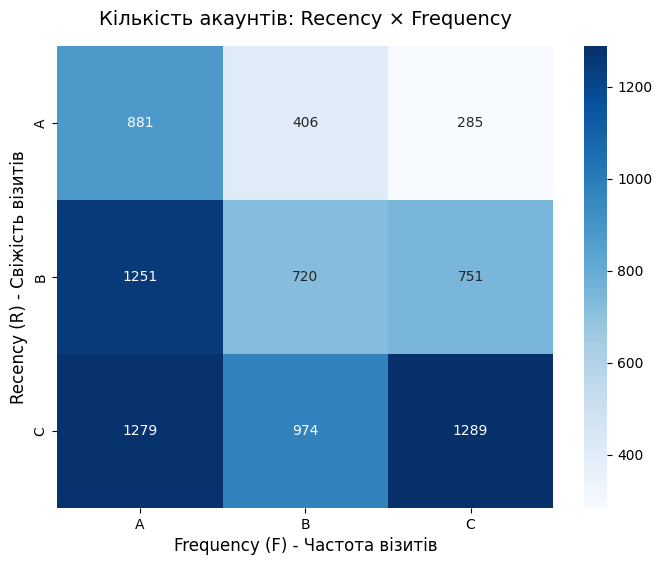

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Створюємо крос-таблицю для Recency та Frequency
pivot = pd.crosstab(df['R'], df['F'])

# Налаштовуємо розмір графіка
plt.figure(figsize=(8, 6))

# Будуємо теплову карту
sns.heatmap(pivot, annot=True, fmt='d', cmap='Blues', cbar=True)

plt.title('Кількість акаунтів: Recency × Frequency', fontsize=14, pad=15)
plt.xlabel('Frequency (F) - Частота візитів', fontsize=12)
plt.ylabel('Recency (R) - Свіжість візитів', fontsize=12)
plt.show()

In [ ]:
display(df['visit_cnt'].describe(percentiles=[.33, .5, .66, .75, .9]))

,visit_cnt
count,7836.000000
mean,23.895100
std,32.196211
min,1.000000
33%,4.000000
50%,10.000000
66%,21.000000
75%,32.000000
90%,68.000000
max,200.000000


In [ ]:
# Оновлюємо F-оцінку на основі квантильного розподілу (3 рівні частини)
df['F'] = pd.qcut(df['visit_cnt'].rank(method='first'), q=3, labels=['C', 'B', 'A'])

# Перераховуємо комбінований RFM-код
df['RFM'] = df['R'] + df['F'].astype(str) + df['M']

# Оновлюємо макро-сегменти
df['segment'] = df.apply(segment, axis=1)

# Розраховуємо новий звіт по макро-сегментах
summary_updated = (df.groupby('segment')
                     .agg(accounts=('account_id', 'count'),
                          avg_visits=('visit_cnt', 'mean'),
                          total_revenue=('revenue', 'sum'),
                          avg_recency=('recency_days', 'mean'))
                     .assign(share_accounts=lambda x: x.accounts / x.accounts.sum() * 100,
                             share_revenue=lambda x: x.total_revenue / x.total_revenue.sum() * 100)
                     .round(1))

display(summary_updated)

,accounts,avg_visits,total_revenue,avg_recency,share_accounts,share_revenue
segment,,,,,,
Lost,3542,18.9,670340,81.1,45.2,35.8
Middle,3046,22.8,693370,43.1,38.9,37.0
Top,1248,40.8,508710,17.6,15.9,27.2


In [ ]:
def segment_v2(row):
    if row['R'] == 'A' and row['F'] in ('A', 'B'):
        return 'Top'
    if row['R'] == 'C' and row['F'] in ('B', 'C'):
        return 'Lost'      # давно і мало — не комунікуємо
    return 'Middle'        # включно з C×A: колишні активні, пробуємо повернути

# Застосовуємо нову логіку сегментації
df['segment'] = df.apply(segment_v2, axis=1)

# Розраховуємо фінальний звіт по оновлених макро-сегментах
summary_v2 = (df.groupby('segment')
                .agg(accounts=('account_id', 'count'),
                     avg_visits=('visit_cnt', 'mean'),
                     total_revenue=('revenue', 'sum'),
                     avg_recency=('recency_days', 'mean'))
                .assign(share_accounts=lambda x: x.accounts / x.accounts.sum() * 100,
                        share_revenue=lambda x: x.total_revenue / x.total_revenue.sum() * 100)
                .round(1))

display(summary_v2)

,accounts,avg_visits,total_revenue,avg_recency,share_accounts,share_revenue
segment,,,,,,
Lost,2615,5.9,154920,82.5,33.4,8.3
Middle,3973,30.4,1208790,51.0,50.7,64.6
Top,1248,40.8,508710,17.6,15.9,27.2


In [ ]:
display(df['recency_days'].describe(percentiles=[.1, .25, .33, .5, .66, .75, .9]))

,recency_days
count,7836.000000
mean,56.213629
std,27.039550
min,0.000000
10%,19.000000
25%,35.000000
33%,43.000000
50%,56.000000
66%,70.000000
75%,77.000000


In [ ]:
# Оновлюємо M-оцінку на основі квантильного розподілу (3 рівні частини)
df['M'] = pd.qcut(df['revenue'].rank(method='first'), q=3, labels=['C', 'B', 'A'])

# Перераховуємо комбінований RFM-код із новими динамічними F та M оцінками
df['RFM'] = df['R'] + df['F'].astype(str) + df['M'].astype(str)

# Перераховуємо макро-сегменти за оновленою логікою (segment_v2)
df['segment'] = df.apply(segment_v2, axis=1)

# Розраховуємо новий звіт по макро-сегментах
summary_v3 = (df.groupby('segment')
                .agg(accounts=('account_id', 'count'),
                     avg_visits=('visit_cnt', 'mean'),
                     total_revenue=('revenue', 'sum'),
                     avg_recency=('recency_days', 'mean'))
                .assign(share_accounts=lambda x: x.accounts / x.accounts.sum() * 100,
                        share_revenue=lambda x: x.total_revenue / x.total_revenue.sum() * 100)
                .round(1))

display(summary_v3)

,accounts,avg_visits,total_revenue,avg_recency,share_accounts,share_revenue
segment,,,,,,
Lost,2615,5.9,154920,82.5,33.4,8.3
Middle,3973,30.4,1208790,51.0,50.7,64.6
Top,1248,40.8,508710,17.6,15.9,27.2


In [ ]:
print(df.groupby('F', observed=True)['visit_cnt'].agg(['min', 'max', 'count']))

   min  max  count
F                 
C    1    4   2612
B    4   21   2612
A   21  200   2612



# Фінальний звіт: Сегментація клієнтів (RFM-аналіз)

Цей розділ містить чистий, упорядкований код та фінальну візуалізацію результатів.



## 1. Завантаження даних та розрахунок базових показників


In [ ]:
import pandas as pd
import glob
import seaborn as sns
import matplotlib.pyplot as plt

# Завантаження даних (з автоматичним пошуком файлу BigQuery)
try:
    file_path = glob.glob('/content/bq-results-*.csv')[0]
    print(f"Успішно знайдено файл даних: {file_path}")
except IndexError:
    file_path = 'rfm_dataset.csv'
    print(f"Файл BigQuery не знайдено, використовуємо резервний: {file_path}")

df_clean = pd.read_csv(file_path, parse_dates=['last_visit_date'])

# Визначення точки відліку та розрахунок Recency в днях
ref_date = df_clean['last_visit_date'].max()
df_clean['recency_days'] = (ref_date - df_clean['last_visit_date']).dt.days

Успішно знайдено файл даних: /content/bq-results-20261015-055426-1792043792548.csv



### Опис кроків предобработки даних

Для підготовки даних до проведення RFM-аналізу виконуються такі кроки:
1. **Динамічний пошук та завантаження файлу**: Код автоматично знаходить останній експортований з BigQuery CSV-файл у директорії `/content/` за маскою імені `bq-results-*.csv`. Це дозволяє уникнути помилок при зміні імені файлу під час повторних вивантажень.
2. **Приведення типів даних**: Стовпець `last_visit_date` конвертується у формат дати (`datetime64`) для коректного проведення математичних операцій.
3. **Визначення точки відліку**: Як базову дату (максимальну точку відліку) взято останній зафіксований візит серед усіх користувачів у поточному наборі даних.
4. **Розрахунок Recency (давності візиту)**: Для кожного підписника розраховується кількість днів, що минули з моменту останнього візиту до визначеної точки відліку (`recency_days`).



## 2. Розрахунок RFM-оцінок за допомогою квантильного підходу


In [ ]:
# 1. Розрахунок R (фіксовані межі)
def r_score_clean(days):
    if days <= 30: return 'A'   # нещодавно
    if days <= 60: return 'B'   # середньо давно
    return 'C'                  # дуже давно

df_clean['R'] = df_clean['recency_days'].apply(r_score_clean)

# 2. Розрахунок F та M через динамічні квантилі (3 рівні частини)
df_clean['F'] = pd.qcut(df_clean['visit_cnt'].rank(method='first'), q=3, labels=['C', 'B', 'A'])
df_clean['M'] = pd.qcut(df_clean['revenue'].rank(method='first'), q=3, labels=['C', 'B', 'A'])

# Загальний RFM код
df_clean['RFM'] = df_clean['R'] + df_clean['F'].astype(str) + df_clean['M'].astype(str)


## 3. Макро-сегментація (Версія 2: Покращена)

У цій версії ми відносимо когорту `C × A` (колишні активні користувачі, які давно не заходили) до сегменту **Middle** для спроби реактивації, а не списуємо їх у **Lost**.


In [ ]:
def segment_final(row):
    if row['R'] == 'A' and row['F'] in ('A', 'B'):
        return 'Top'
    if row['R'] == 'C' and row['F'] in ('B', 'C'):
        return 'Lost'      # давно і мало — не комунікуємо
    return 'Middle'        # включно з C×A: колишні активні, пробуємо повернути

df_clean['segment'] = df_clean.apply(segment_final, axis=1)

summary_final = (df_clean.groupby('segment')
                .agg(accounts=('account_id', 'count'),
                     avg_visits=('visit_cnt', 'mean'),
                     total_revenue=('revenue', 'sum'),
                     avg_recency=('recency_days', 'mean'))
                .assign(share_accounts=lambda x: x.accounts / x.accounts.sum() * 100,
                        share_revenue=lambda x: x.total_revenue / x.total_revenue.sum() * 100)
                .round(1))

display(summary_final)

,accounts,avg_visits,total_revenue,avg_recency,share_accounts,share_revenue
segment,,,,,,
Lost,2615,5.9,154920,82.5,33.4,8.3
Middle,3973,30.4,1208790,51.0,50.7,64.6
Top,1248,40.8,508710,17.6,15.9,27.2



## 4. Візуалізація результатів


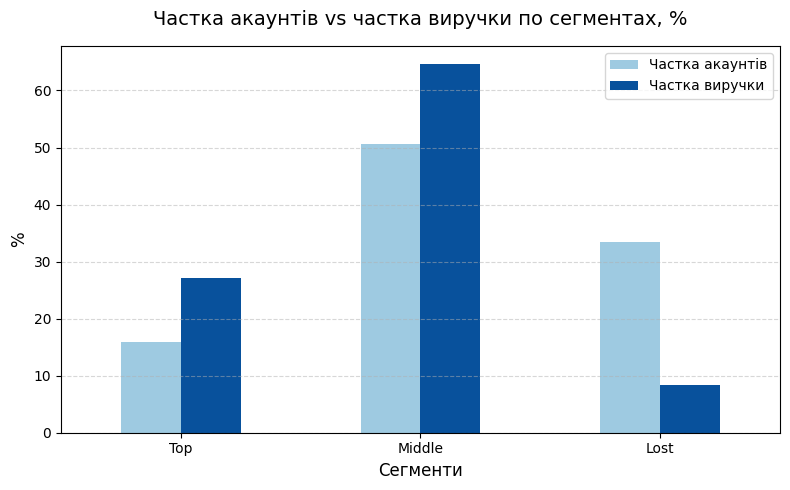

In [ ]:
# Побудова графіка порівняння часток акаунтів та виручки
summary_final[['share_accounts', 'share_revenue']].loc[['Top', 'Middle', 'Lost']].plot(
    kind='bar', figsize=(8, 5), rot=0, color=['#9ecae1', '#08519c'])

plt.title('Частка акаунтів vs частка виручки по сегментах, %', fontsize=14, pad=15)
plt.ylabel('%', fontsize=12)
plt.xlabel('Сегменти', fontsize=12)
plt.legend(['Частка акаунтів', 'Частка виручки'])
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


## 5. Висновки та бізнес-рекомендації

**Загальний контекст:**
Дані охоплюють приблизно 4 місяці (давність останнього відкриття варіюється від 0 до 116 днів, медіана становить 56 днів). Розподіл кількості відкритих листів сильно скошений (медіана — 10, середнє — 24, максимум — 200), саме тому пороги для показника **Frequency** було визначено динамічно за допомогою терцилів (квантилів), а не фіксованих меж. Показник **Recency** було розбито відповідно до вимог технічного завдання на три класи: 0–30 днів / 31–60 днів / 61+ днів.

### Аналіз та стратегія для макро-сегментів:

1. **Top (16% бази, 27% виручки):**
   * *Опис:* Користувачі, які відкривали листи в середньому 18 днів тому та мають високу частоту взаємодії (~41 відкритий лист).
   * *Рекомендація:* Заохочувати їхню лояльність. Використовувати персональні пропозиції, ранній доступ до нових продуктів та бонуси за постійну активність.

2. **Middle (51% бази, 65% виручки):**
   * *Опис:* Основне джерело прибутку компанії. Сюди ми свідомо перенесли колишніх дуже активних користувачів, які давно не взаємодіяли з розсилками ($R = 'C'$, $F = 'A'$).
   * *Рекомендація:* Це гарячі кандидати на проведення win-back (реактіваційних) кампаній. Оскільки вони вже мають історію активності в минулому, їх значно легше та дешевше повернути, ніж залучити нових клієнтів.

3. **Lost (33% бази, 8% виручки):**
   * *Опис:* Клієнти, які давно не відкривали листи й загалом мали вкрай низьку активність (~6 відкритих листів за весь час).
   * *Рекомендація:* Повністю припинити регулярні комунікації з цим сегментом. Це майже не вплине на загальний прибуток (вони генерують лише 8% доходу), проте суттєво покращить показники доставлюваності листів (deliverability) та репутацію вашого домену у поштових провайдерів.

**Технічні обмеження:**
Показник `revenue` у поточному наборі даних є умовним ($10 за кожне відкриття листа), тому шкала монетизації (M) повністю повторює структуру частоти (F) та не несе додаткового унікального сигналу. Проте у разі появи реальних транзакційних даних побудована логіка дозволить миттєво врахувати фінансовий внесок кожного клієнта.
